In [1]:
from helper_functions.get_data_dictionary_target_X_y_imports import *

Loaded: 
      data: the entire dataset.
      dictionary: the data dictionary.
      X: the features columns with 'inhospital_mortality', 'studyid_adm', 'lengthadm' dropped.
      y: the target column.


In [2]:
special_features = dictionary[dictionary.Feature.str.startswith('comorbidity_')].Feature.tolist()
df = data[special_features + [target]]

In [3]:
for col in special_features:
    df[col] = np.where(df[col]=='Checked', 1, 0)
    print(df[col].unique())

[0 1]
[0 1]
[0 1]
[0]
[0 1]
[0 1]
[0 1]
[0 1]
[0 1]
[0 1]
[1 0]
[0 1]


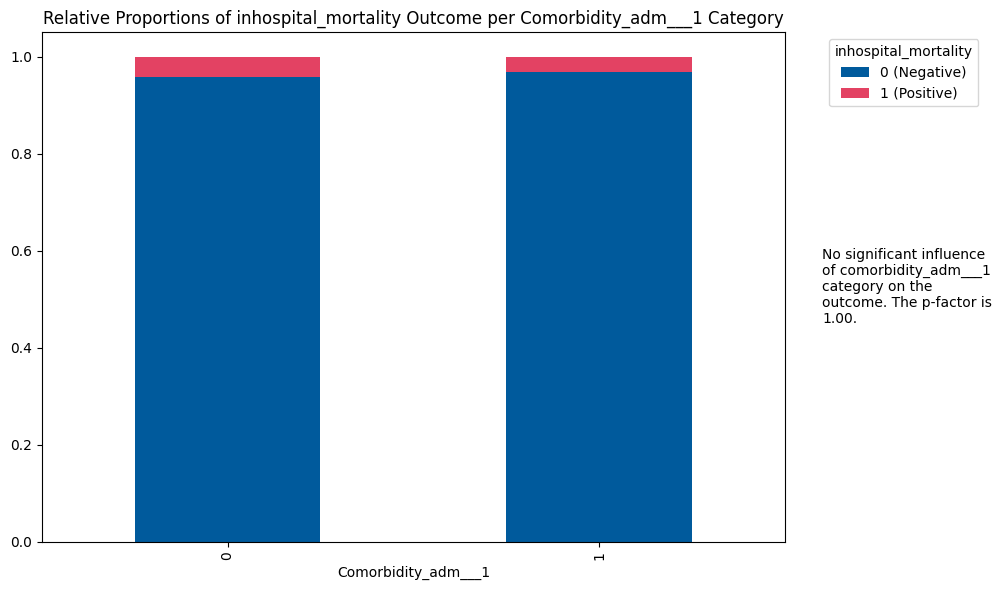

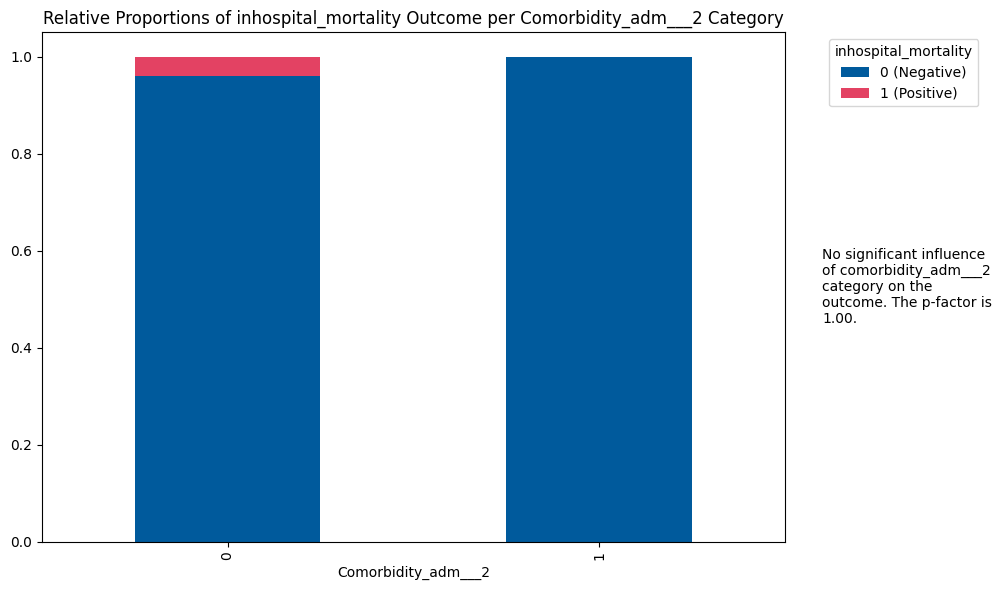

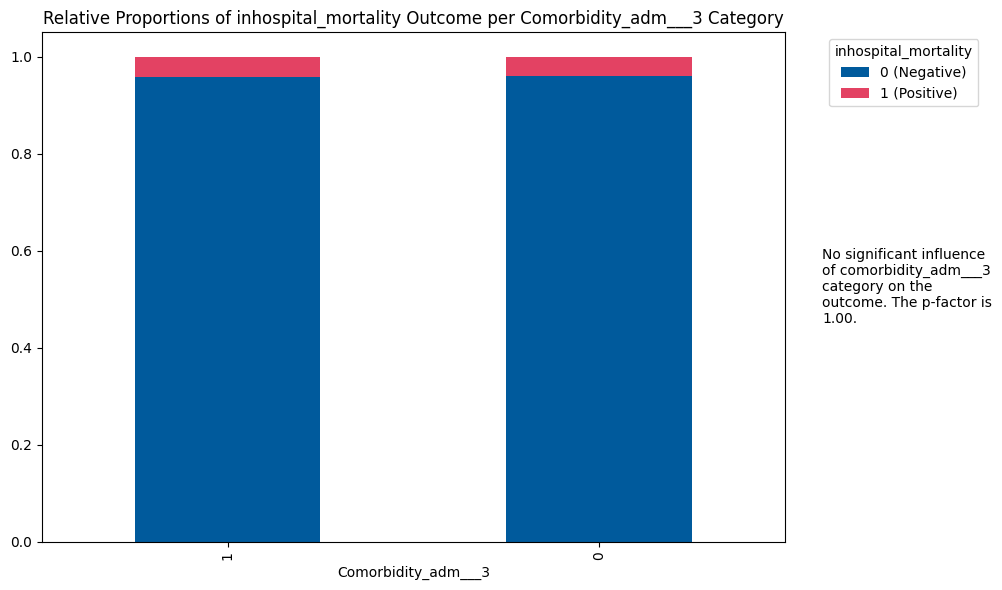

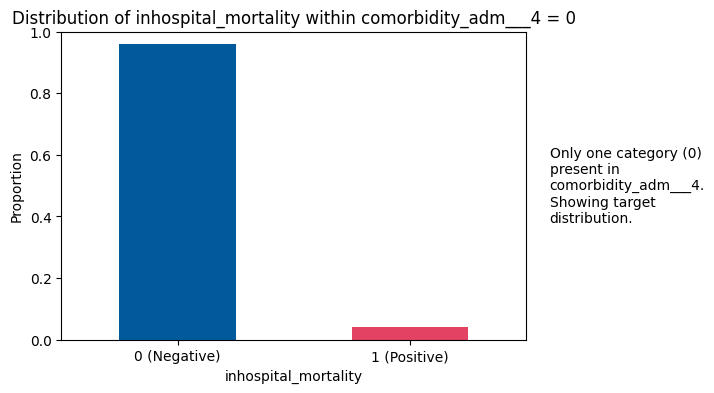

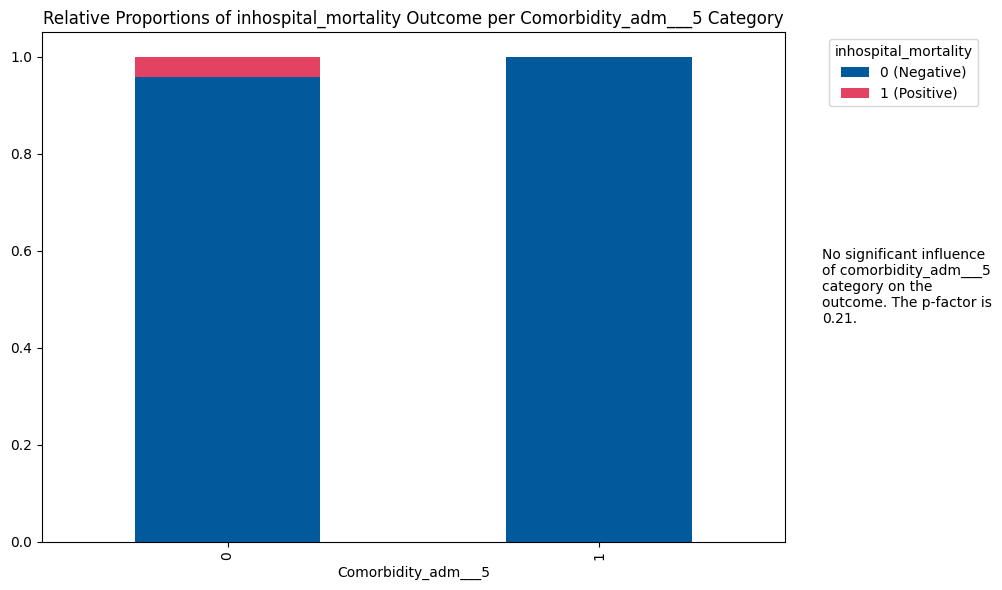

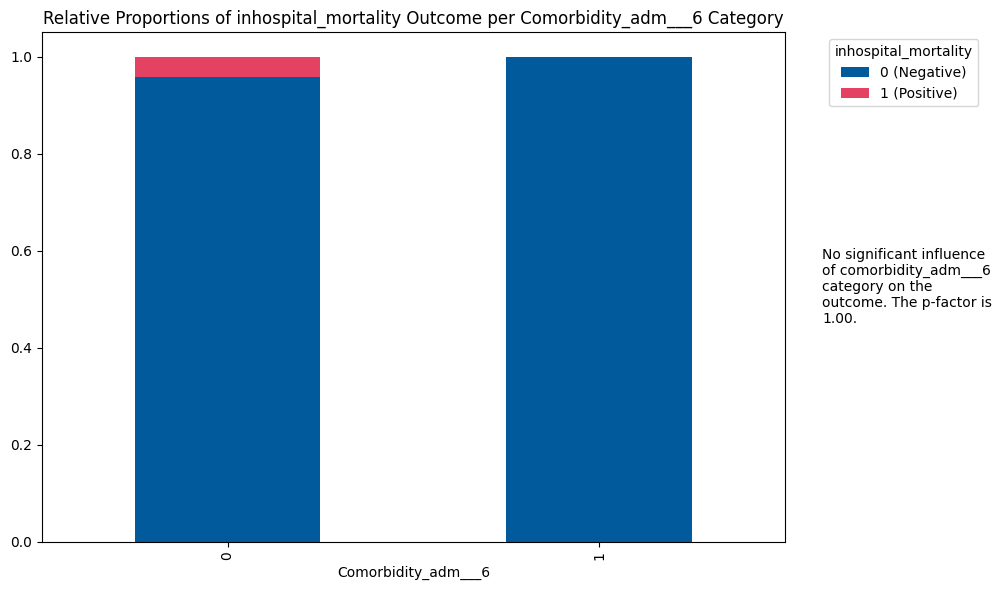

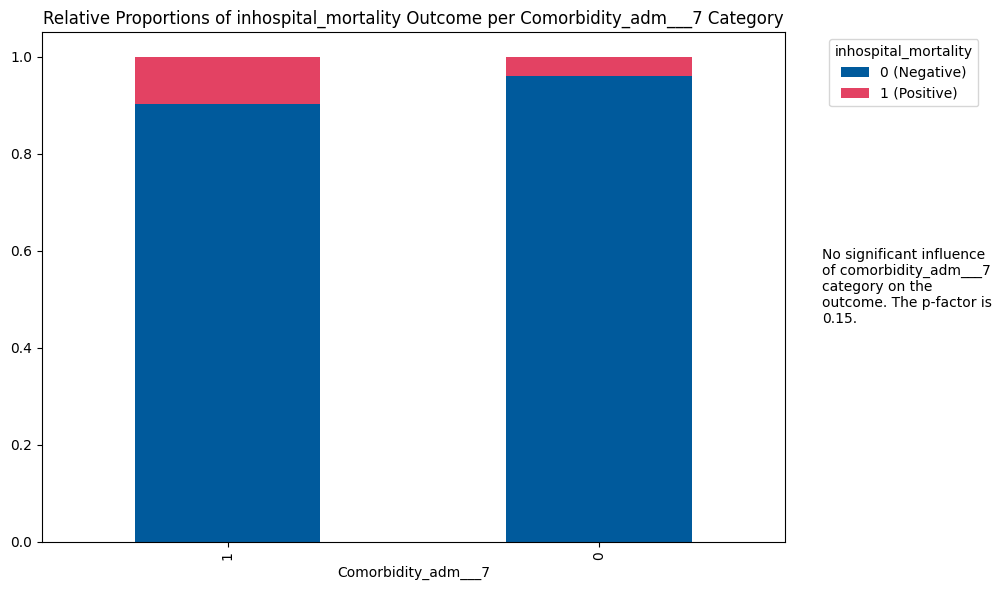

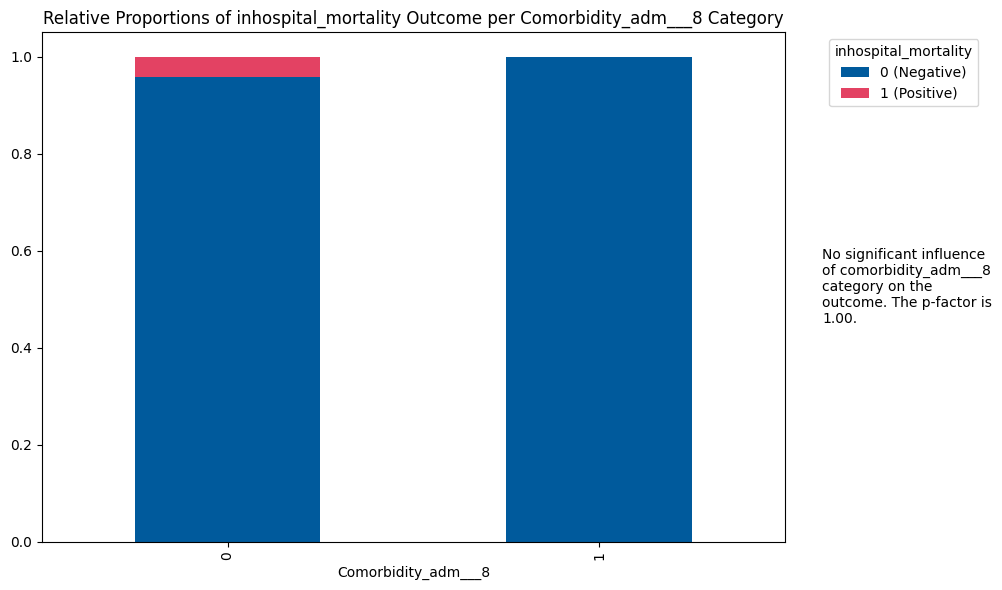

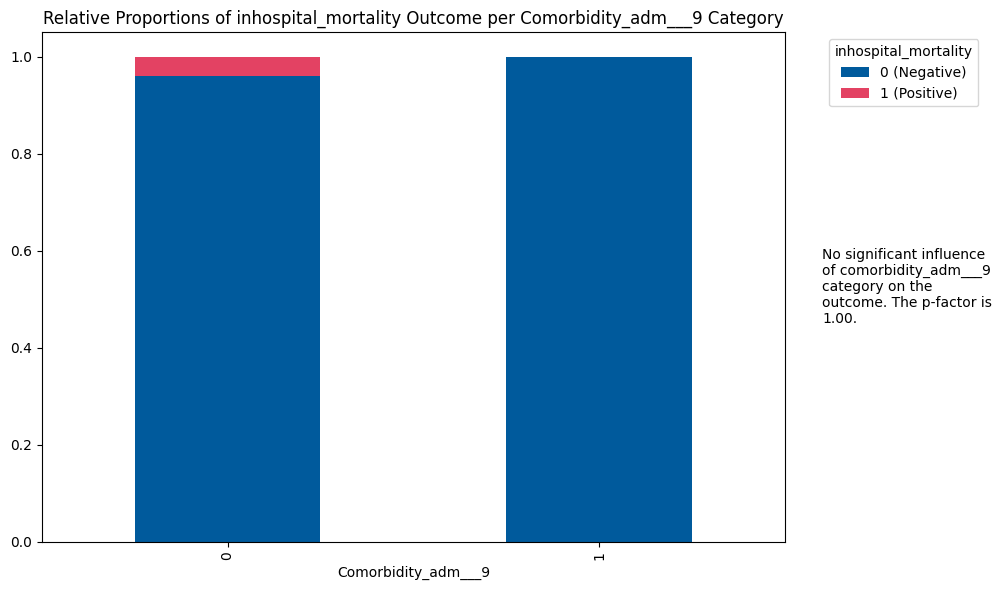

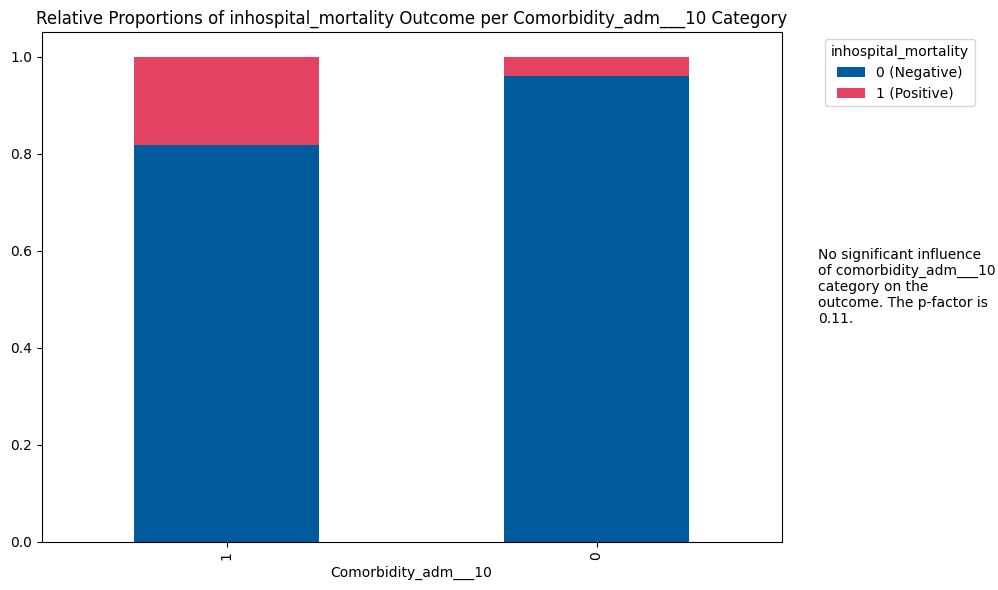

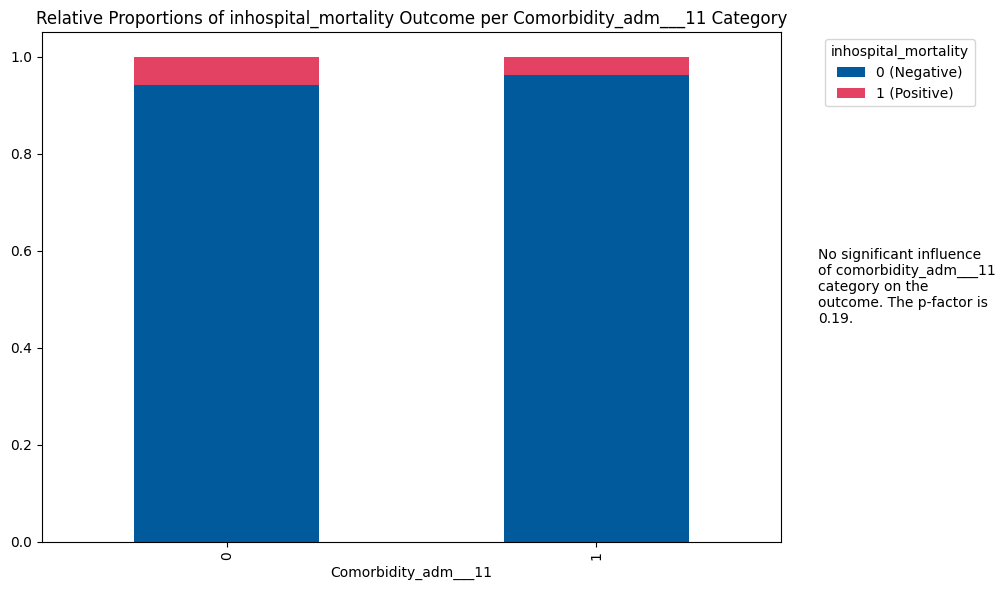

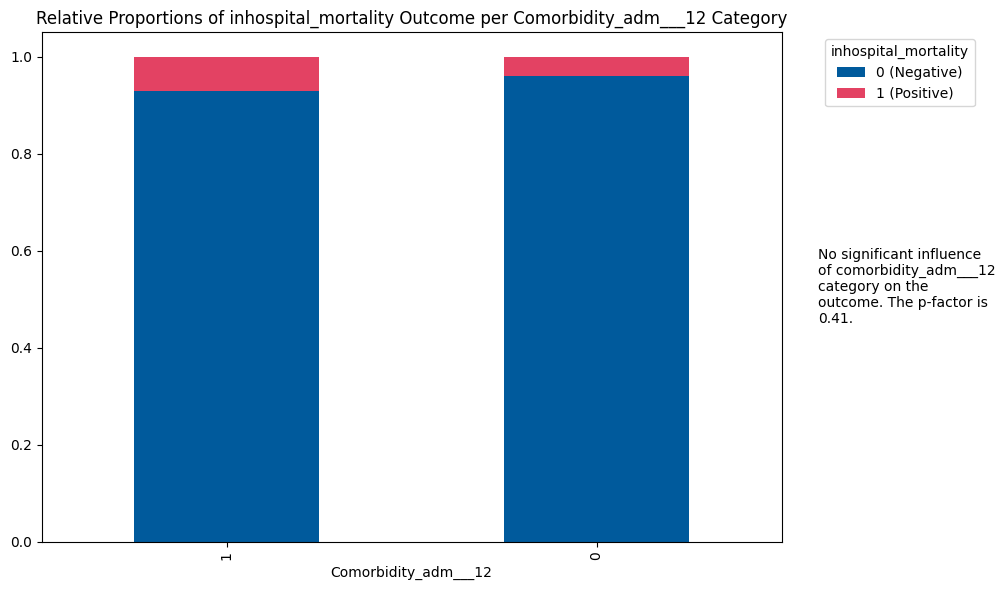

In [4]:
for col in special_features:
    try:
        categorical_analysis(col, df, target, color=['#005A9C', '#E34263'])
    except Exception as e:
        print(col)
        print(e)

In [23]:
import itertools
from tqdm.notebook import tqdm
import math

results = {}

for k in tqdm(range(1, 12)):  # Looping from K = 2 to 11
    feature_combinations = itertools.combinations(special_features, k)
    num_combinations = math.comb(12, k)
    
    combined_features = {
        "_".join(cols): sum(df[col] for col in cols)
        for cols in feature_combinations
    }
    
    for feature_name, feature_values in tqdm(combined_features.items(), total=num_combinations, leave=False):
        tmp = feature_values.copy()
        tmp.name = feature_name
        tmp = tmp.to_frame()
        tmp[target] = df[target]
        
        result = categorical_analysis(feature_name, tmp, target, 
                                      return_result_only=True)
        
        results[feature_name] = result

for k, v in results.items():
    if v and v > 0.3:
        print(k, v)


  0%|          | 0/11 [00:00<?, ?it/s]

  0%|          | 0/12 [00:00<?, ?it/s]

  0%|          | 0/66 [00:00<?, ?it/s]

  0%|          | 0/220 [00:00<?, ?it/s]

  0%|          | 0/495 [00:00<?, ?it/s]

  0%|          | 0/792 [00:00<?, ?it/s]

... (2 outputs left out)

  0%|          | 0/495 [00:00<?, ?it/s]

  0%|          | 0/220 [00:00<?, ?it/s]

  0%|          | 0/66 [00:00<?, ?it/s]

  0%|          | 0/12 [00:00<?, ?it/s]